In [1]:
import sys, os, json, warnings
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import mlflow
from sklearn.metrics import roc_auc_score, average_precision_score

from src.preprocessing.sort_and_split import load_raw_data, sort_by_time, time_split
from src.preprocessing.missing_values import encode_m_columns, fill_nan_for_trees
from src.feature_engineering.uid_features import build_uid_features
from src.feature_engineering.frequency_encoding import fit_freq_encoder, apply_freq_encoder
from src.feature_engineering.uid_aggregations import build_uid_aggregations
from src.feature_engineering.amount_features import build_amount_features
from src.feature_engineering.time_features import build_time_features
from src.feature_engineering.email_features import build_email_features
from src.feature_engineering.device_features import build_device_features
from src.feature_engineering.d_features import build_d_features
from src.feature_engineering.c_features import build_c_features
from src.feature_engineering.m_features import build_m_features
from src.feature_engineering.velocity_features import build_velocity_features_offline
from src.utils.reduce_mem import reduce_mem_usage

print('Imports OK')

Imports OK


In [ ]:
mlflow.set_tracking_uri('http://127.0.0.1:5000')
mlflow.set_experiment('02_Feature_Engineering')

LGBM_PARAMS = {
    'n_estimators': 3000, 'num_leaves': 127, 'learning_rate': 0.02,
    'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_samples': 20,
    'scale_pos_weight': 27, 'metric': 'average_precision',
    'objective': 'binary', 'random_state': 42, 'verbose': -1, 'n_jobs': -1,
}

EXCLUDE = ['TransactionID', 'isFraud', 'uid1', 'uid2', 'uid3', 'uid_magic',
           'card4', 'card6', 'ProductCD', 'DeviceType', 'P_emaildomain',
           'R_emaildomain', 'DeviceInfo', 'device_os', 'device_browser',
           'P_email_tld', 'R_email_tld']

ablation_results = []  # track AUC-PR at each step

In [ ]:
def quick_train_eval(train_df, val_df, run_name, fe_description, params=LGBM_PARAMS):
    """Train LGBM and log to MLflow. Returns val_aupr."""
    feat_cols = [c for c in train_df.columns
                 if c not in EXCLUDE and train_df[c].dtype != object]

    print('Reducing memory...')
    train_df = reduce_mem_usage(train_df)
    val_df = reduce_mem_usage(val_df)
    X_tr = train_df[feat_cols].values
    y_tr = train_df['isFraud'].values
    X_vl = val_df[feat_cols].values
    y_vl = val_df['isFraud'].values

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params(params)
        mlflow.log_params({
            'n_features': len(feat_cols),
            'fe_step':    fe_description,
        })

        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_tr, y_tr, eval_set=[(X_vl, y_vl)],
            callbacks=[lgb.early_stopping(200, verbose=False),
                       lgb.log_evaluation(500)]
        )

        preds    = model.predict_proba(X_vl)[:, 1]
        val_auc  = roc_auc_score(y_vl, preds)
        val_aupr = average_precision_score(y_vl, preds)

        mlflow.log_metrics({'val_auc_roc': val_auc, 'val_auc_pr': val_aupr,
                            'best_iter': model.best_iteration_})

        print(f'[{run_name}]  AUC-ROC={val_auc:.5f}  AUC-PR={val_aupr:.5f}  n_feat={len(feat_cols)}')
        return val_aupr, model, feat_cols

In [4]:
import sys, os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())


In [5]:
# ── Load and sort ──────────────────────────────────────────────────────────────
train_df, test_df = load_raw_data('data/raw')
train_df = sort_by_time(train_df)
train_df = encode_m_columns(train_df, nan_value=-1)

2026-06-14 20:12:06.428 | INFO     | src.preprocessing.sort_and_split:load_raw_data:33 - Loading raw CSVs from data\raw
2026-06-14 20:12:36.010 | INFO     | src.preprocessing.sort_and_split:load_raw_data:43 - Train shape: (590540, 434)  |  Test shape: (506691, 433)
2026-06-14 20:12:40.665 | INFO     | src.preprocessing.sort_and_split:sort_by_time:64 - Sorted by TransactionDT.  Day range: 1 – 182  |  Hour distribution: 13.9±7.6
2026-06-14 20:12:41.107 | INFO     | src.preprocessing.missing_values:encode_m_columns:47 - Encoded 9 M-columns (NaN → -1).  Sample: {'M1': np.int64(1), 'M2': np.int64(1), 'M3': np.int64(1)}


In [6]:
# ── Step 2a: Add UID magic ────────────────────────────────────────────────────
train_df = build_uid_features(train_df)
train_df['uid1_freq']     = train_df.groupby('uid1')['uid1'].transform('count')
train_df['uid_magic_freq']= train_df.groupby('uid_magic')['uid_magic'].transform('count')

tr_a, vl_a = time_split(fill_nan_for_trees(train_df.copy()), 0.75)
aupr_2a, _, _ = quick_train_eval(tr_a, vl_a, '2a_uid_magic', 'baseline + uid_magic + uid_freq')
ablation_results.append({'step': '2a_uid_magic', 'aupr': aupr_2a})

2026-06-14 20:12:56.073 | INFO     | src.feature_engineering.uid_features:build_uid_features:61 - uid1:  217850 unique values (36.9% of rows)
2026-06-14 20:12:56.170 | INFO     | src.feature_engineering.uid_features:build_uid_features:61 - uid2:  273919 unique values (46.4% of rows)
2026-06-14 20:12:56.242 | INFO     | src.feature_engineering.uid_features:build_uid_features:61 - uid_magic:  217850 unique values (36.9% of rows)
2026-06-14 20:12:56.324 | INFO     | src.feature_engineering.uid_features:build_uid_features:61 - uid3:  246669 unique values (41.8% of rows)
2026-06-14 20:13:02.068 | INFO     | src.preprocessing.missing_values:fill_nan_for_trees:86 - Tree NaN fill (-999): 104178894 NaN values filled across 416 numeric columns.
2026-06-14 20:13:07.652 | INFO     | src.preprocessing.sort_and_split:time_split:94 - Time split at day 130 (q=0.75).  Train: 445173 rows (15630 fraud)  |  Val: 145367 rows (5033 fraud)


Reducing memory...
Memory usage of dataframe is 1504.61 MB
Memory usage after optimization is: 780.75 MB
Decreased by 48.1%
Memory usage of dataframe is 491.31 MB
Memory usage after optimization is: 254.95 MB
Decreased by 48.1%
[500]	valid_0's average_precision: 0.552818
[1000]	valid_0's average_precision: 0.574159
[1500]	valid_0's average_precision: 0.582401
[2a_uid_magic]  AUC-ROC=0.90809  AUC-PR=0.58242  n_feat=414
🏃 View run 2a_uid_magic at: http://127.0.0.1:5000/#/experiments/2/runs/947e60a020b64ef4a1b684c5925dec01
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [7]:
# ── Step 2b: Add frequency encoding ──────────────────────────────────────────
train_split_raw, val_split_raw = time_split(train_df, 0.75)
FREQ_COLS = ['card1','card2','card3','card5','addr1','addr2',
             'P_emaildomain','R_emaildomain','DeviceInfo','uid1','uid_magic']
freq_maps = fit_freq_encoder(train_split_raw, cols=FREQ_COLS)
for part in [train_split_raw, val_split_raw]:
    apply_freq_encoder(part, freq_maps)

tr_b = fill_nan_for_trees(train_split_raw.copy())
vl_b = fill_nan_for_trees(val_split_raw.copy())
aupr_2b, _, _ = quick_train_eval(tr_b, vl_b, '2b_freq_encoding', '2a + frequency encoding')
ablation_results.append({'step': '2b_freq_encoding', 'aupr': aupr_2b})

2026-06-14 20:15:08.876 | INFO     | src.preprocessing.sort_and_split:time_split:94 - Time split at day 130 (q=0.75).  Train: 445173 rows (15630 fraud)  |  Val: 145367 rows (5033 fraud)
2026-06-14 20:15:08.893 | DEBUG    | src.feature_engineering.frequency_encoding:fit_freq_encoder:66 - Freq map for 'card1': 12504 unique values, top-5 freqs: [0.026322351085982302, 0.02349199075415625, 0.018078365040108003, 0.01723150325828386, 0.013122988141688737]
2026-06-14 20:15:08.900 | DEBUG    | src.feature_engineering.frequency_encoding:fit_freq_encoder:66 - Freq map for 'card2': 500 unique values, top-5 freqs: [0.08293624272063906, 0.07707397632739275, 0.07279703100158076, 0.06442790438803185, 0.0395988111232513]
2026-06-14 20:15:08.906 | DEBUG    | src.feature_engineering.frequency_encoding:fit_freq_encoder:66 - Freq map for 'card3': 106 unique values, top-5 freqs: [0.8811027343310454, 0.09913356588275009, 0.0026960729154945425, 0.002360751659727692, 0.0021717114886913467]
2026-06-14 20:15:08.

Reducing memory...
Memory usage of dataframe is 1535.17 MB
Memory usage after optimization is: 797.73 MB
Decreased by 48.0%
Memory usage of dataframe is 501.30 MB
Memory usage after optimization is: 260.49 MB
Decreased by 48.0%
[500]	valid_0's average_precision: 0.563984
[1000]	valid_0's average_precision: 0.574845
[2b_freq_encoding]  AUC-ROC=0.91548  AUC-PR=0.57978  n_feat=423
🏃 View run 2b_freq_encoding at: http://127.0.0.1:5000/#/experiments/2/runs/2a1979bce1f64eeab07d4476703dae20
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [8]:
# ── Step 2c: Add D features (D_norm + uid agg) ─────────────────────────────
for part in [train_split_raw, val_split_raw]:
    build_d_features(part)

tr_c = fill_nan_for_trees(train_split_raw.copy())
vl_c = fill_nan_for_trees(val_split_raw.copy())
aupr_2c, _, _ = quick_train_eval(tr_c, vl_c, '2c_d_features', '2b + D_norm + D_uid_agg')
ablation_results.append({'step': '2c_d_features', 'aupr': aupr_2c})

2026-06-14 20:17:59.980 | INFO     | src.feature_engineering.d_features:build_d_features:40 - D normalisation done: 15 D_norm columns added.  Example D1_norm stats: mean=28.23, std=154.38.
2026-06-14 20:18:01.878 | INFO     | src.feature_engineering.d_features:build_d_features:55 - D uid aggregations added for 8 priority columns.
2026-06-14 20:18:01.903 | INFO     | src.feature_engineering.d_features:build_d_features:40 - D normalisation done: 15 D_norm columns added.  Example D1_norm stats: mean=-47.16, std=173.99.
2026-06-14 20:18:02.369 | INFO     | src.feature_engineering.d_features:build_d_features:55 - D uid aggregations added for 8 priority columns.
2026-06-14 20:18:07.856 | INFO     | src.preprocessing.missing_values:fill_nan_for_trees:86 - Tree NaN fill (-999): 84335162 NaN values filled across 456 numeric columns.
2026-06-14 20:18:09.580 | INFO     | src.preprocessing.missing_values:fill_nan_for_trees:86 - Tree NaN fill (-999): 27796975 NaN values filled across 456 numeric co

Reducing memory...
Memory usage of dataframe is 1640.46 MB
Memory usage after optimization is: 850.37 MB
Decreased by 48.2%
Memory usage of dataframe is 535.68 MB
Memory usage after optimization is: 277.68 MB
Decreased by 48.2%
[500]	valid_0's average_precision: 0.520151
[1000]	valid_0's average_precision: 0.532445
[1500]	valid_0's average_precision: 0.549912
[2c_d_features]  AUC-ROC=0.90461  AUC-PR=0.54994  n_feat=454
🏃 View run 2c_d_features at: http://127.0.0.1:5000/#/experiments/2/runs/feb40ce10ac64b088a9684f034121336
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [9]:
# ── Step 2d: Add C and M features ────────────────────────────────────────────
for part in [train_split_raw, val_split_raw]:
    build_c_features(part)
    build_m_features(part)

tr_d = fill_nan_for_trees(train_split_raw.copy())
vl_d = fill_nan_for_trees(val_split_raw.copy())
aupr_2d, _, _ = quick_train_eval(tr_d, vl_d, '2d_cm_features', '2c + C_ratios + M_mismatch + uid_agg')
ablation_results.append({'step': '2d_cm_features', 'aupr': aupr_2d})

2026-06-14 20:20:38.685 | INFO     | src.feature_engineering.c_features:build_c_features:56 - C features added: ratios, C3_flag, 42 uid-agg columns.  Priority aggs: ['C1_uid_mean', 'C9_uid_mean', 'C11_uid_mean', 'C13_uid_mean'].
2026-06-14 20:20:40.816 | INFO     | src.feature_engineering.m_features:build_m_features:57 - M features added: M_match_count, M_mismatch_count, M_nan_count, 9 M_uid_mean cols.  Mean match: 2.27, mean mismatch: 1.33.
2026-06-14 20:20:41.838 | INFO     | src.feature_engineering.c_features:build_c_features:56 - C features added: ratios, C3_flag, 42 uid-agg columns.  Priority aggs: ['C1_uid_mean', 'C9_uid_mean', 'C11_uid_mean', 'C13_uid_mean'].
2026-06-14 20:20:42.477 | INFO     | src.feature_engineering.m_features:build_m_features:57 - M features added: M_match_count, M_mismatch_count, M_nan_count, 9 M_uid_mean cols.  Mean match: 3.26, mean mismatch: 1.89.
2026-06-14 20:20:49.563 | INFO     | src.preprocessing.missing_values:fill_nan_for_trees:86 - Tree NaN fill 

Reducing memory...
Memory usage of dataframe is 1837.45 MB
Memory usage after optimization is: 943.77 MB
Decreased by 48.6%
Memory usage of dataframe is 600.00 MB
Memory usage after optimization is: 308.18 MB
Decreased by 48.6%
[500]	valid_0's average_precision: 0.524454
[1000]	valid_0's average_precision: 0.532287
[1500]	valid_0's average_precision: 0.544783
[2d_cm_features]  AUC-ROC=0.90032  AUC-PR=0.54500  n_feat=512
🏃 View run 2d_cm_features at: http://127.0.0.1:5000/#/experiments/2/runs/3abc4735e88944039defb1a2f24ad6cc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [10]:
# ── Step 2e: Add amount deviation ────────────────────────────────────────────
# Need uid agg first
all_df = pd.concat([train_split_raw, val_split_raw], ignore_index=True)
all_df = build_uid_aggregations(all_df, train_idx=np.arange(len(train_split_raw)))
train_split_raw = all_df.iloc[:len(train_split_raw)].copy()
val_split_raw   = all_df.iloc[len(train_split_raw):].copy()

for part in [train_split_raw, val_split_raw]:
    build_amount_features(part)

tr_e = fill_nan_for_trees(train_split_raw.copy())
vl_e = fill_nan_for_trees(val_split_raw.copy())
aupr_2e, _, _ = quick_train_eval(tr_e, vl_e, '2e_amount_features', '2d + amt_log + decimal + zscore')
ablation_results.append({'step': '2e_amount_features', 'aupr': aupr_2e})

2026-06-14 20:24:15.795 | INFO     | src.feature_engineering.uid_aggregations:build_uid_aggregations:132 - UID aggregation features added: 92 total.
2026-06-14 20:24:21.616 | INFO     | src.feature_engineering.amount_features:build_amount_features:64 - Amount features added: log, decimal, amt_over_uid_mean, amt_over_uid_max, amt_over_card1_mean, amt_zscore.
2026-06-14 20:24:21.651 | INFO     | src.feature_engineering.amount_features:build_amount_features:64 - Amount features added: log, decimal, amt_over_uid_mean, amt_over_uid_max, amt_over_card1_mean, amt_zscore.
2026-06-14 20:24:32.369 | INFO     | src.preprocessing.missing_values:fill_nan_for_trees:86 - Tree NaN fill (-999): 82416089 NaN values filled across 545 numeric columns.
2026-06-14 20:24:34.636 | INFO     | src.preprocessing.missing_values:fill_nan_for_trees:86 - Tree NaN fill (-999): 27196844 NaN values filled across 545 numeric columns.


Reducing memory...
Memory usage of dataframe is 1939.34 MB
Memory usage after optimization is: 993.02 MB
Decreased by 48.8%
Memory usage of dataframe is 633.27 MB
Memory usage after optimization is: 324.26 MB
Decreased by 48.8%
[500]	valid_0's average_precision: 0.605746
[2e_amount_features]  AUC-ROC=0.91412  AUC-PR=0.61001  n_feat=543
🏃 View run 2e_amount_features at: http://127.0.0.1:5000/#/experiments/2/runs/4ad9be6ec37a4e16adb910c7e419bfc9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [12]:
# ── Step 2f: Add cyclic time + email + device ─────────────────────────────────
for part in [train_split_raw, val_split_raw]:
    build_time_features(part)
    build_email_features(part)
    build_device_features(part)

tr_f = fill_nan_for_trees(train_split_raw.copy())
vl_f = fill_nan_for_trees(val_split_raw.copy())
aupr_2f, _, _ = quick_train_eval(tr_f, vl_f, '2f_time_email_device', '2e + cyclic_time + email + device_regex')
ablation_results.append({'step': '2f_time_email_device', 'aupr': aupr_2f})

2026-06-14 20:28:41.200 | INFO     | src.feature_engineering.time_features:build_time_features:55 - Time features added: hour, weekday, week, is_weekend, is_late_night, hour_sin/cos, dow_sin/cos, week_sin/cos, month.
2026-06-14 20:28:42.341 | INFO     | src.feature_engineering.email_features:build_email_features:56 - Email features added: email_match=32.36%, P_email_is_free=71.66%, email_trusted=66.18%.
2026-06-14 20:28:43.208 | INFO     | src.feature_engineering.device_features:build_device_features:59 - Device features added: device_os (6 unique), device_browser (7 unique), device_mobile (9.9%).
2026-06-14 20:28:43.235 | INFO     | src.feature_engineering.time_features:build_time_features:55 - Time features added: hour, weekday, week, is_weekend, is_late_night, hour_sin/cos, dow_sin/cos, week_sin/cos, month.
2026-06-14 20:28:43.609 | INFO     | src.feature_engineering.email_features:build_email_features:56 - Email features added: email_match=28.78%, P_email_is_free=70.81%, email_trus

Reducing memory...
Memory usage of dataframe is 2014.07 MB
Memory usage after optimization is: 1021.89 MB
Decreased by 49.3%
Memory usage of dataframe is 657.67 MB
Memory usage after optimization is: 333.69 MB
Decreased by 49.3%
[500]	valid_0's average_precision: 0.604194
[1000]	valid_0's average_precision: 0.616805
[2f_time_email_device]  AUC-ROC=0.90615  AUC-PR=0.61915  n_feat=561
🏃 View run 2f_time_email_device at: http://127.0.0.1:5000/#/experiments/2/runs/a32d1cc8ba2c4358a6ce505d393cb0ba
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [13]:
# ── Step 2g: Add velocity features ───────────────────────────────────────────
print('Building velocity features (slowest step ~5-10 min)…')
train_split_raw = build_velocity_features_offline(train_split_raw)
val_split_raw   = build_velocity_features_offline(val_split_raw)

tr_g = fill_nan_for_trees(train_split_raw.copy())
vl_g = fill_nan_for_trees(val_split_raw.copy())
aupr_2g, final_model, final_feat_cols = quick_train_eval(
    tr_g, vl_g, '2g_velocity', '2f + uid_tx_1h + uid_amt_24h + uid_gap_last'
)
ablation_results.append({'step': '2g_velocity', 'aupr': aupr_2g})

2026-06-14 20:32:06.759 | INFO     | src.feature_engineering.velocity_features:build_velocity_features_offline:50 - Building offline velocity features (group=uid1, windows=(3600, 86400))…


Building velocity features (slowest step ~5-10 min)…


2026-06-14 20:32:09.016 | INFO     | src.feature_engineering.velocity_features:build_velocity_features_offline:115 - Velocity features added: gap_last, avg_gap + 4 window features.
2026-06-14 20:32:09.094 | INFO     | src.feature_engineering.velocity_features:build_velocity_features_offline:50 - Building offline velocity features (group=uid1, windows=(3600, 86400))…
2026-06-14 20:32:09.500 | INFO     | src.feature_engineering.velocity_features:build_velocity_features_offline:115 - Velocity features added: gap_last, avg_gap + 4 window features.
2026-06-14 20:32:20.929 | INFO     | src.preprocessing.missing_values:fill_nan_for_trees:86 - Tree NaN fill (-999): 82416089 NaN values filled across 569 numeric columns.
2026-06-14 20:32:23.861 | INFO     | src.preprocessing.missing_values:fill_nan_for_trees:86 - Tree NaN fill (-999): 27196844 NaN values filled across 569 numeric columns.


Reducing memory...
Memory usage of dataframe is 2031.05 MB
Memory usage after optimization is: 1029.96 MB
Decreased by 49.3%
Memory usage of dataframe is 663.22 MB
Memory usage after optimization is: 336.46 MB
Decreased by 49.3%
[500]	valid_0's average_precision: 0.601109
[2g_velocity]  AUC-ROC=0.91967  AUC-PR=0.60833  n_feat=567
🏃 View run 2g_velocity at: http://127.0.0.1:5000/#/experiments/2/runs/176293ac6e7c49199051f82f79342c7a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


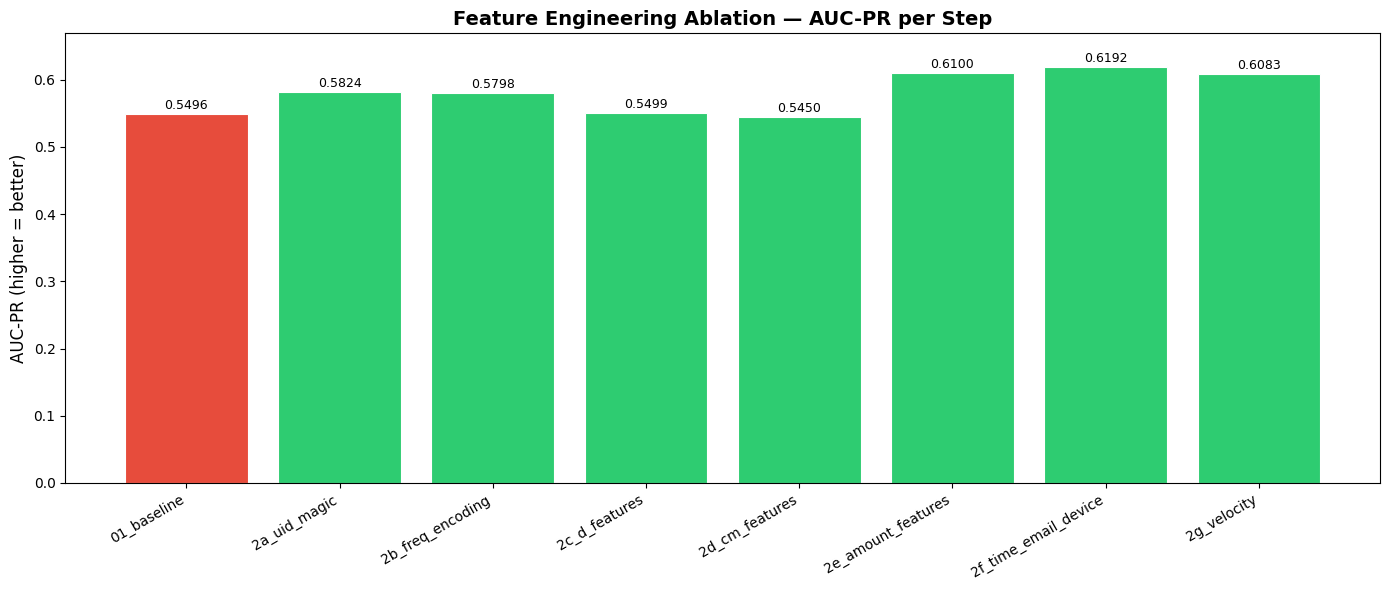

Ablation chart saved.


In [14]:
# ── Plot ablation waterfall chart ─────────────────────────────────────────────
baseline_aupr = 0.0  # load from exp01 if available
try:
    with open('artifacts/metrics/exp01_baseline.json') as f:
        baseline_aupr = json.load(f)['val_auc_pr']
except FileNotFoundError:
    pass

all_steps = [{'step': '01_baseline', 'aupr': baseline_aupr}] + ablation_results
df_abl = pd.DataFrame(all_steps)

fig, ax = plt.subplots(figsize=(14, 6))
colors = ['#e74c3c' if i == 0 else '#2ecc71' for i in range(len(df_abl))]
bars = ax.bar(df_abl['step'], df_abl['aupr'], color=colors, edgecolor='white', linewidth=0.8)

# Annotate bars
for bar, aupr in zip(bars, df_abl['aupr']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            f'{aupr:.4f}', ha='center', va='bottom', fontsize=9)

ax.set_ylabel('AUC-PR (higher = better)', fontsize=12)
ax.set_title('Feature Engineering Ablation — AUC-PR per Step', fontsize=14, fontweight='bold')
ax.set_ylim(0, min(1.0, df_abl['aupr'].max() + 0.05))
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

os.makedirs('artifacts/shap', exist_ok=True)
plt.savefig('artifacts/shap/exp02_fe_ablation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Ablation chart saved.')

In [15]:
# ── Log ablation chart + summary to MLflow ────────────────────────────────────
with mlflow.start_run(run_name='fe_ablation_summary') as run:
    mlflow.log_artifact('artifacts/shap/exp02_fe_ablation.png')
    mlflow.log_metrics({f'aupr_{r["step"]}': r['aupr'] for r in ablation_results})
    mlflow.log_metric('final_aupr', aupr_2g)
    mlflow.log_metric('improvement_vs_baseline', aupr_2g - baseline_aupr)

# ── Save metrics JSON ─────────────────────────────────────────────────────────
metrics = {
    'experiment': '02_feature_engineering',
    'n_features': len(final_feat_cols),
    'val_auc_pr': round(aupr_2g, 5),
    'ablation': [{'step': r['step'], 'aupr': round(r['aupr'], 5)} for r in all_steps],
}
with open('artifacts/metrics/exp02_feature_engineering.json', 'w') as f:
    json.dump(metrics, f, indent=2)

print(f'\nExp 2 complete. Final AUC-PR: {aupr_2g:.5f}')
print(f'Improvement over baseline: +{aupr_2g - baseline_aupr:.5f}')
print('Run next: 03_deep_learning.ipynb')

🏃 View run fe_ablation_summary at: http://127.0.0.1:5000/#/experiments/2/runs/dc299acfd1214fd9a8be18d8edc39353
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

Exp 2 complete. Final AUC-PR: 0.60833
Improvement over baseline: +0.05869
Run next: 03_deep_learning.ipynb


In [16]:
# 1. Extract feature values and true labels from the validation set
X_vl = vl_g[final_feat_cols].values
y_vl = vl_g['isFraud'].values

# 2. Generate model probabilities
y_prob = final_model.predict_proba(X_vl)[:, 1]

# 3. Calculate Precision-Recall curve & find optimal threshold for F1-score
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_vl, y_prob)

# Avoid division by zero
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-8)
optimal_idx = f1_scores.argmax()
optimal_threshold = thresholds[optimal_idx]

print(f"Optimal Threshold (Max F1): {optimal_threshold:.4f}")
print(f"Max F1-Score: {f1_scores[optimal_idx]:.4f}")
print(f"Precision at optimal threshold: {precisions[optimal_idx]:.4f}")
print(f"Recall at optimal threshold: {recalls[optimal_idx]:.4f}")


Optimal Threshold (Max F1): 0.6182
Max F1-Score: 0.5990
Precision at optimal threshold: 0.7268
Recall at optimal threshold: 0.5094


In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

# 1. Get features, labels, and probabilities
X_vl = vl_g[final_feat_cols].values
y_vl = vl_g['isFraud'].values
y_prob = final_model.predict_proba(X_vl)[:, 1]

# 2. Calculate Overall Threshold-Independent Metrics
auc_roc = roc_auc_score(y_vl, y_prob)
auc_pr = average_precision_score(y_vl, y_prob)

print("=== Overall Model Performance ===")
print(f"AUC-ROC: {auc_roc * 100:.2f}%")
print(f"AUC-PR:  {auc_pr * 100:.2f}%\n")

# 3. Define the thresholds to check
thresholds = [0.40, 0.50, 0.618, 0.70]

# 4. Print Threshold Comparison Table
print("=== Performance by Threshold ===")
print("| Threshold | Precision | Recall | F1     |")
print("| --------- | --------- | ------ | ------ |")

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)
    precision = precision_score(y_vl, y_pred, zero_division=0) * 100
    recall = recall_score(y_vl, y_pred, zero_division=0) * 100
    f1 = f1_score(y_vl, y_pred, zero_division=0) * 100
    print(f"| {t:.3f}     | {precision:5.1f}%   | {recall:5.1f}%  | {f1:5.1f}%  |")


=== Overall Model Performance ===
AUC-ROC: 91.97%
AUC-PR:  60.83%

=== Performance by Threshold ===
| Threshold | Precision | Recall | F1     |
| --------- | --------- | ------ | ------ |
| 0.400     |  47.7%   |  61.8%  |  53.8%  |
| 0.500     |  59.5%   |  56.5%  |  57.9%  |
| 0.618     |  72.6%   |  50.9%  |  59.9%  |
| 0.700     |  80.5%   |  46.3%  |  58.8%  |


In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

# 1. Get features, labels, and probabilities
X_vl = vl_g[final_feat_cols].values
y_vl = vl_g['isFraud'].values
y_prob = final_model.predict_proba(X_vl)[:, 1]

# 2. Calculate Overall Threshold-Independent Metrics
auc_roc = roc_auc_score(y_vl, y_prob)
auc_pr = average_precision_score(y_vl, y_prob)

print("=== Overall Model Performance ===")
print(f"AUC-ROC: {auc_roc * 100:.2f}%")
print(f"AUC-PR:  {auc_pr * 100:.2f}%\n")

# 3. Define the thresholds to check
thresholds = [0.40, 0.50, 0.618, 0.70]

# 4. Print Threshold Comparison Table
print("=== Performance by Threshold ===")
print("| Threshold | Precision | Recall | F1     |")
print("| --------- | --------- | ------ | ------ |")

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)
    precision = precision_score(y_vl, y_pred, zero_division=0) * 100
    recall = recall_score(y_vl, y_pred, zero_division=0) * 100
    f1 = f1_score(y_vl, y_pred, zero_division=0) * 100
    print(f"| {t:.3f}     | {precision:5.1f}%   | {recall:5.1f}%  | {f1:5.1f}%  |")


=== Overall Model Performance ===
AUC-ROC: 91.97%
AUC-PR:  60.83%

=== Performance by Threshold ===
| Threshold | Precision | Recall | F1     |
| --------- | --------- | ------ | ------ |
| 0.400     |  47.7%   |  61.8%  |  53.8%  |
| 0.500     |  59.5%   |  56.5%  |  57.9%  |
| 0.618     |  72.6%   |  50.9%  |  59.9%  |
| 0.700     |  80.5%   |  46.3%  |  58.8%  |
